In [1]:
import sys
import os
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

from util import load_sensor_dict
import at3d
import numpy as np

In [2]:
## Test 00
# iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/tmp/test00/iterations/iter002.nc'
# obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
# sf = 1
# inverse_covariance = sf * np.diag(np.ones(4))
# uncertainty = at3d.uncertainties.Uncertainty(inverse_covariance, 'L2')
# cost_at3d = 0.00013939955825691136

## Test 03
# iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/tmp/test03/iterations/iter002.nc'
# obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
# sf = 10
# inverse_covariance = sf * np.diag(np.ones(4))
# uncertainty = at3d.uncertainties.Uncertainty(inverse_covariance, 'L2')
# cost_at3d = 0.0013939955618910693

## default
iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V00/default/iterations/iter020.nc'
obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
uncertainty = at3d.uncertainties.RadiometricNoiseUncertainty(1e-6, 1e-3)
cost_at3d = 61.492604923369214

/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/at3d/uncertainties.py:69: UserWarning: `inverse_covariance` of errors in uninvertible.It cannot be used to generate noise and will cause an exception to be raised if attempted.
  warnings.warn("`inverse_covariance` of errors in uninvertible."


In [3]:
F_sensor = load_sensor_dict(iterfile)
y_sensor = load_sensor_dict(obs_file)

In [4]:
def obs_vec(sensor, uncertainty):
    vec = np.array([])
    w = np.array([])
    for s in sensor['MISR']['sensor_list']:
        uncertainty.calculate_uncertainties(s)
        vec = np.append(vec, s.I.data)
        Iw = s.isel(num_uncertainty=0, num_uncertainty2=0).uncertainties.data
        w = np.append(w, Iw)
    return vec, w

In [5]:
F, _ = obs_vec(F_sensor, uncertainty)
y, w = obs_vec(y_sensor, uncertainty)

In [6]:
W = np.diag(w)
cost_self = (1/(2*F_sensor.nmeasurements)) * np.matmul(y-F, np.matmul(W, y-F))

In [7]:
print('ME: {}'.format(cost_self))
print('Ans: {}'.format(cost_at3d))
print('Ans - ME: {}'.format(cost_at3d - cost_self))
print('ME / Ans: {}'.format(cost_self/cost_at3d))
print('Ans / Me: {}'.format(cost_at3d/cost_self))

ME: 61.49260486703557
Ans: 61.492604923369214
Ans - ME: 5.633364708046429e-08
ME / Ans: 0.9999999990838956
Ans / Me: 1.0000000009161045


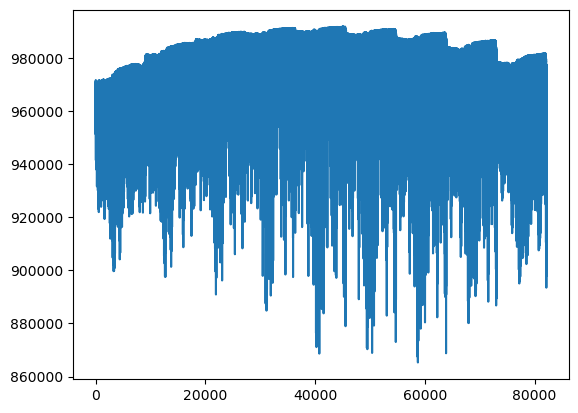

In [8]:
import matplotlib.pyplot as plt

plt.plot(w)